In [1]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt

ROOT = Path.cwd()
if not (ROOT / "data").exists():
    ROOT = ROOT.parent

DATA_PATH = ROOT / "data" / "mau" / "issue_descriptions.csv"
df = pd.read_csv(DATA_PATH)

print("Kích thước dữ liệu:", df.shape)
display(df.head())

Kích thước dữ liệu: (2400, 4)


,desc_id,issue_desc,issue_category,center_id
0,1,kh nói máy có hơi nước trong camera khách chưa...,NUOC_VAO,3
1,2,kh nói khay sim bị móp xảy ra sau khi rơi,KHAC,6
2,3,tinh trang: man hinh nhap nhay lien tuc,MAN_HINH,1
3,4,tình trạng: ứng dụng tự thoát liên tục máy còn...,PHAN_MEM,6
4,5,sạc không vào điện,SAC,1


In [2]:
print("Các cột:", df.columns.tolist())
print("Số dòng trùng lặp:", df.duplicated().sum())
display(df.isna().sum().to_frame("Số giá trị thiếu"))

Các cột: ['desc_id', 'issue_desc', 'issue_category', 'center_id']
Số dòng trùng lặp: 0


,Số giá trị thiếu
desc_id,0
issue_desc,0
issue_category,0
center_id,0


In [3]:
lengths = df["issue_desc"].fillna("").astype(str).str.split().str.len()

display(lengths.describe().to_frame("Số từ"))
print(f"Tỷ lệ mô tả dưới 10 từ: {(lengths < 10).mean() * 100:.2f}%")

,Số từ
count,2400.000000
mean,11.612917
std,3.819249
min,3.000000
25%,8.000000
50%,12.000000
75%,15.000000
max,22.000000


Tỷ lệ mô tả dưới 10 từ: 29.79%


,Số mẫu,Tỷ lệ (%)
issue_category,,
MAN_HINH,518,21.58
PIN,434,18.08
KHAC,428,17.83
PHAN_MEM,380,15.83
SAC,375,15.62
NUOC_VAO,265,11.04


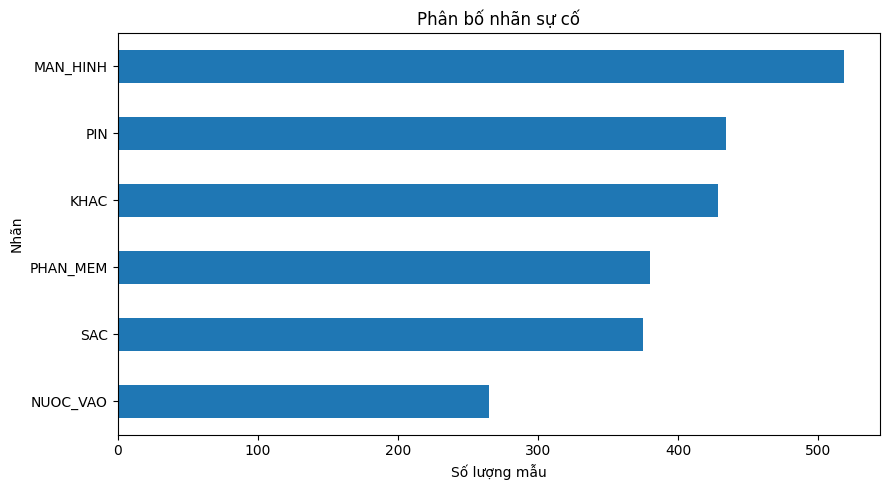

In [4]:
counts = df["issue_category"].value_counts()

display(pd.DataFrame({
    "Số mẫu": counts,
    "Tỷ lệ (%)": (counts / len(df) * 100).round(2)
}))

ax = counts.sort_values().plot(kind="barh", figsize=(9, 5))
ax.set_title("Phân bố nhãn sự cố")
ax.set_xlabel("Số lượng mẫu")
ax.set_ylabel("Nhãn")
plt.tight_layout()
plt.show()